# Iris Dataset Analysis

An exploratory analysis of the classic Iris dataset: 150 flowers from three species (*Iris setosa*, *Iris versicolor*, *Iris virginica*), each described by four measurements (sepal length/width and petal length/width, in cm).

The notebook first rebuilds the full dataset from its five source files and answers a few specific lookup questions. It then goes further with an extended exploratory analysis covering distributions, variability, correlations, outliers and **which measurements actually tell the species apart**.

## Data Sources

- **Sepal All:** https://docs.google.com/spreadsheets/d/e/2PACX-1vT58ekmHTwptX7Bs4QOy6YByA1HMvYTACeeIjrKhHE0Pg1K_3egewHMKMh02zN9D5-yHVXfvuaa3s5u/pub?gid=2028782809&single=true&output=csv
    - **Unnamed: 0:** Unused column, created when this sub-dataset was generated.
    - **Id:** Record ID.
    - **SepalLengthCm:** Sepal length (cm).
    - **SepalWidthCm:** Sepal width (cm).

- **Petal All:** https://docs.google.com/spreadsheets/d/e/2PACX-1vQinLXShrOz4ExNaW1bSQVuvbbhIzJW7G0kkkD2SvqSD6STjLrQQiftgI7BGe10sBZi0CNr2_sJpQAz/pub?gid=1580010789&single=true&output=csv
    - **PetalLengthCm:** Petal length (cm).
    - **PetalWidthCm:** Petal width (cm).

- **Iris Virginica:** https://docs.google.com/spreadsheets/d/e/2PACX-1vSK39MwduGPHYNgw5yViezoLYCVDKMCWIHzjnt3GZNaxHPFOQLr2q6no_tyqTsOk-VfXleslfGVe9eJ/pub?gid=314231613&single=true&output=csv
- **Iris Versicolor:** https://docs.google.com/spreadsheets/d/e/2PACX-1vTcSFgLnabqIrgIc5WlwvnbbvyyJsgZjR-0E0-4TR-5aHgv_0EP6yNWglkkls3AXM2qHCR5VYzWCoTM/pub?gid=715607857&single=true&output=csv
- **Iris Setosa:** https://docs.google.com/spreadsheets/d/e/2PACX-1vSjqJpdgy2X_oDUUqQ0sSaFKqnnf8MYU4KgJSYgHaHmq0Wb1weMOsJXh-rICHmkLcaTkOwzMYLeh959/pub?gid=2003684803&single=true&output=csv

    Each species file has just `Unnamed: 0`, `Id`, and `Species`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

In [2]:
sepal_all = pd.read_csv('https://docs.google.com/spreadsheets/d/e/2PACX-1vT58ekmHTwptX7Bs4QOy6YByA1HMvYTACeeIjrKhHE0Pg1K_3egewHMKMh02zN9D5-yHVXfvuaa3s5u/pub?gid=2028782809&single=true&output=csv')
petal_all = pd.read_csv('https://docs.google.com/spreadsheets/d/e/2PACX-1vQinLXShrOz4ExNaW1bSQVuvbbhIzJW7G0kkkD2SvqSD6STjLrQQiftgI7BGe10sBZi0CNr2_sJpQAz/pub?gid=1580010789&single=true&output=csv')
virginica = pd.read_csv('https://docs.google.com/spreadsheets/d/e/2PACX-1vSK39MwduGPHYNgw5yViezoLYCVDKMCWIHzjnt3GZNaxHPFOQLr2q6no_tyqTsOk-VfXleslfGVe9eJ/pub?gid=314231613&single=true&output=csv')
versicolor = pd.read_csv('https://docs.google.com/spreadsheets/d/e/2PACX-1vTcSFgLnabqIrgIc5WlwvnbbvyyJsgZjR-0E0-4TR-5aHgv_0EP6yNWglkkls3AXM2qHCR5VYzWCoTM/pub?gid=715607857&single=true&output=csv')
setosa = pd.read_csv('https://docs.google.com/spreadsheets/d/e/2PACX-1vSjqJpdgy2X_oDUUqQ0sSaFKqnnf8MYU4KgJSYgHaHmq0Wb1weMOsJXh-rICHmkLcaTkOwzMYLeh959/pub?gid=2003684803&single=true&output=csv')

In [3]:
measurements_df = sepal_all.merge(petal_all, on=['Id', 'Unnamed: 0'])
species_df = pd.concat([setosa, versicolor, virginica], ignore_index=True)

iris_df = species_df.merge(measurements_df, on=['Id', 'Unnamed: 0'])
iris_df = iris_df[['Id', 'Species', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']]
iris_df.head()

,Id,Species,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,1,Iris-setosa,5.1,3.5,1.4,0.2
1,2,Iris-setosa,4.9,3.0,1.4,0.2
2,3,Iris-setosa,4.7,3.2,1.3,0.2
3,4,Iris-setosa,4.6,3.1,1.5,0.2
4,5,Iris-setosa,5.0,3.6,1.4,0.2


## Dataset Overview & Data Quality

**Analytical Question:** Is the combined dataset complete, correctly typed and balanced across species before we start comparing them?

In [4]:
# Shared settings reused by the analysis below
features = ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
species_order = ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
species_colors = dict(zip(species_order, ['#4C72B0', '#DD8452', '#55A868']))
feature_labels = {
    'SepalLengthCm': 'Sepal length (cm)', 'SepalWidthCm': 'Sepal width (cm)',
    'PetalLengthCm': 'Petal length (cm)', 'PetalWidthCm': 'Petal width (cm)',
}

iris_df.info()

print('\nDuplicate Ids:', iris_df['Id'].duplicated().sum())
print('Rows repeating another flower\'s measurements (same species):',
      iris_df.duplicated(subset=['Species'] + features, keep=False).sum())

print('\nFlowers per species:')
print(iris_df['Species'].value_counts().to_string())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   Species        150 non-null    object 
 2   SepalLengthCm  150 non-null    float64
 3   SepalWidthCm   150 non-null    float64
 4   PetalLengthCm  150 non-null    float64
 5   PetalWidthCm   150 non-null    float64
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB

Duplicate Ids: 0
Rows repeating another flower's measurements (same species): 5

Flowers per species:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50


**Interpretation:** The dataset is clean: 150 rows, no missing values, all four measurements are numeric and every `Id` is unique. Each species has exactly 50 flowers, so the classes are perfectly balanced and species-level averages can be compared directly without any weighting. A small number of rows repeat another flower's measurements exactly (same species, different `Id`); they are genuine separate observations, so they are kept.

## Average Sepal Length (Virginica) vs Average Petal Length (Setosa)

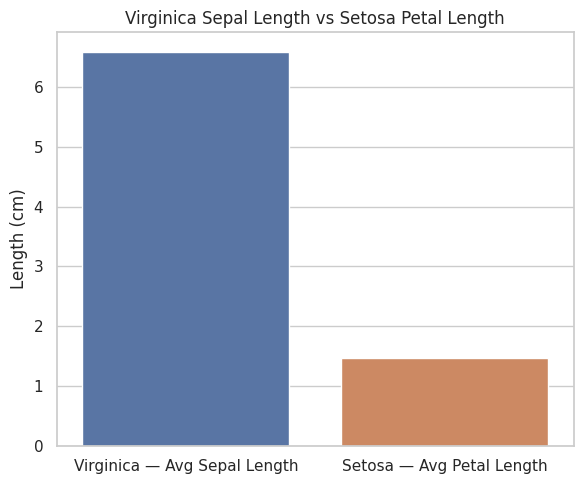

In [5]:
virginica_sepal_len = iris_df.loc[iris_df['Species'] == 'Iris-virginica', 'SepalLengthCm'].mean()
setosa_petal_len = iris_df.loc[iris_df['Species'] == 'Iris-setosa', 'PetalLengthCm'].mean()

bar_labels = ['Virginica — Avg Sepal Length', 'Setosa — Avg Petal Length']

plt.figure(figsize=(6, 5))
sns.barplot(
    x=bar_labels,
    y=[virginica_sepal_len, setosa_petal_len],
    hue=bar_labels,
    palette=['#4C72B0', '#DD8452'],
    legend=False,
)
plt.ylabel('Length (cm)')
plt.title('Virginica Sepal Length vs Setosa Petal Length')
plt.tight_layout()
plt.show()

## Complete, Shuffled Dataset

Combine all five source files into one dataset with columns in the order `Id, Species, SepalLengthCm, SepalWidthCm, PetalLengthCm, PetalWidthCm`, shuffled so `Id` is not in sorted order.

In [6]:
iris_shuffled = iris_df.sample(frac=1, random_state=42).reset_index(drop=True)
iris_shuffled.head()

,Id,Species,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,74,Iris-versicolor,6.1,2.8,4.7,1.2
1,19,Iris-setosa,5.7,3.8,1.7,0.3
2,119,Iris-virginica,7.7,2.6,6.9,2.3
3,79,Iris-versicolor,6.0,2.9,4.5,1.5
4,77,Iris-versicolor,6.8,2.8,4.8,1.4


## Min/Max Sepal & Petal Width — Setosa vs Versicolor

In [7]:
width_stats = (
    iris_df
    .groupby('Species')
    .agg({'SepalWidthCm': ['min', 'max'], 'PetalWidthCm': ['min', 'max']})
    .loc[['Iris-setosa', 'Iris-versicolor']]
)
width_stats

SepalWidthCm      PetalWidthCm     
                         min  max          min  max
Species                                            
Iris-setosa              2.3  4.4          0.1  0.6
Iris-versicolor          2.0  3.4          1.0  1.8

In [8]:
for species in ['Iris-setosa', 'Iris-versicolor']:
    label = species.replace('Iris-', '').capitalize()
    sepal_min = width_stats.loc[species, ('SepalWidthCm', 'min')]
    sepal_max = width_stats.loc[species, ('SepalWidthCm', 'max')]

    print(f'Minimum Sepal width of {label} is {sepal_min}')
    print(f'Maximum Sepal width of {label} is {sepal_max}')
    print()
    print('*' * 50)
    print()

Minimum Sepal width of Setosa is 2.3
Maximum Sepal width of Setosa is 4.4

**************************************************

Minimum Sepal width of Versicolor is 2.0
Maximum Sepal width of Versicolor is 3.4

**************************************************



# From Description to Deeper Analysis

The analysis so far has covered the dataset's structure, its quality, and a few targeted lookups. We now move beyond individual lookups to broader patterns:<br> how the species differ, how the measurements are distributed and vary, how they relate to one another, and which features separate the species most clearly.

## 1. How do the three species compare on each measurement?

**Analytical Question:** What is the typical value (mean, median) and the spread (standard deviation) of each measurement within each species?

In [9]:
species_summary = (
    iris_df.groupby('Species')[features]
    .agg(['mean', 'median', 'std'])
    .round(2)
    .T
)
species_summary

Species               Iris-setosa  Iris-versicolor  Iris-virginica
SepalLengthCm mean           5.01             5.94            6.59
              median         5.00             5.90            6.50
              std            0.35             0.52            0.64
SepalWidthCm  mean           3.42             2.77            2.97
              median         3.40             2.80            3.00
              std            0.38             0.31            0.32
PetalLengthCm mean           1.46             4.26            5.55
              median         1.50             4.35            5.55
              std            0.17             0.47            0.55
PetalWidthCm  mean           0.24             1.33            2.03
              median         0.20             1.30            2.00
              std            0.11             0.20            0.27

**Interpretation:** Petal size increases steadily from setosa to versicolor to virginica (mean petal length 1.46 → 4.26 → 5.55 cm, mean petal width 0.25 → 1.33 → 2.03 cm), and the differences between species means are considerably larger than the spread inside a species (petal standard deviations range from 0.11 to 0.55). Sepal width breaks the pattern: setosa has the *widest* sepals (3.43 cm) even though it is the smallest species on every other measurement, so the species cannot simply be ranked from small to large on every feature. Means and medians are almost identical in each group, so the distributions are roughly symmetric and the mean is a reliable summary.

## 2. How are the measurements distributed, and where do the species overlap?

**Analytical Question:** Which measurements show clearly separated distributions for the three species, and which overlap heavily?

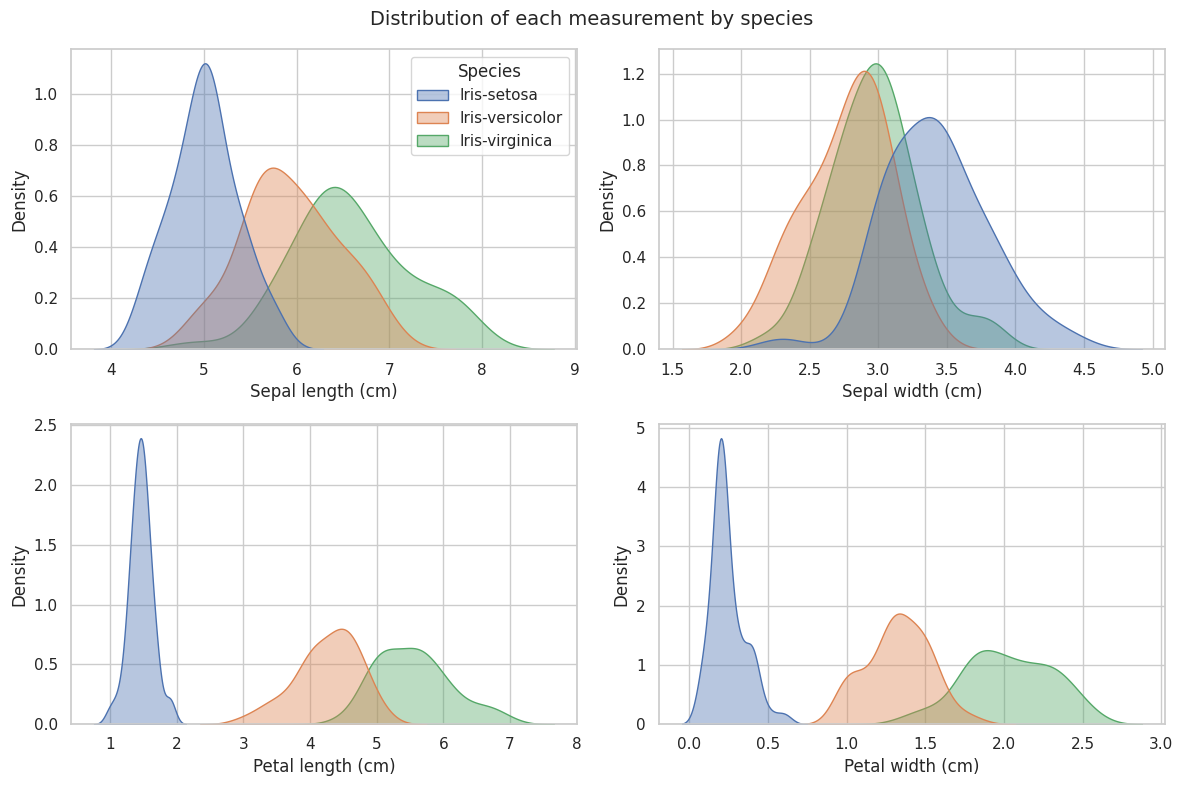

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.ravel(), features):
    sns.kdeplot(
        data=iris_df, x=feature, hue='Species', hue_order=species_order,
        palette=species_colors, fill=True, alpha=0.4, common_norm=False, ax=ax,
    )
    ax.set_xlabel(feature_labels[feature])

for ax in axes.ravel()[1:]:
    ax.get_legend().remove()  # keep a single legend

fig.suptitle('Distribution of each measurement by species', fontsize=14)
plt.tight_layout()
plt.show()

**Interpretation:** Petal length and petal width each show three distinct humps: setosa sits far to the left with no overlap at all, while versicolor and virginica overlap only around the edges of their distributions. Sepal length overlaps noticeably for all three species, and sepal width overlaps almost completely (setosa is only shifted slightly higher). The petal measurements therefore carry most of the information about species, while sepal width is nearly uninformative on its own.

## 3. Which measurements vary most within a species?

**Analytical Question:** Relative to its typical size, how much does each measurement vary inside each species, and how does that compare with the variation across all 150 flowers combined? (Coefficient of variation = standard deviation ÷ mean, which makes measurements on different scales comparable.)

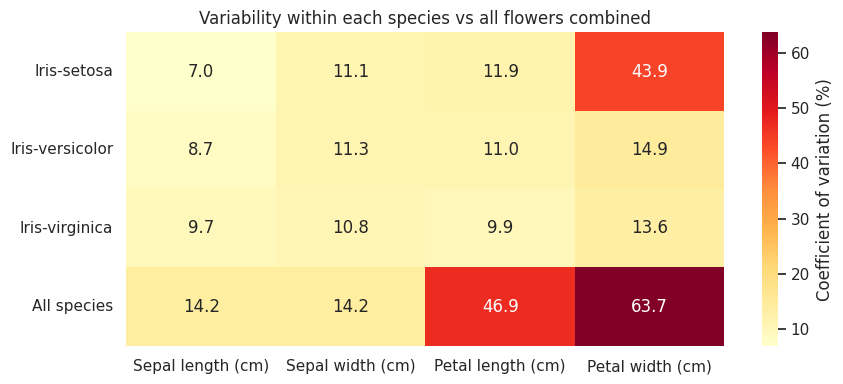

In [11]:
group_cv = iris_df.groupby('Species')[features].std() / iris_df.groupby('Species')[features].mean()
overall_cv = iris_df[features].std() / iris_df[features].mean()

cv_pct = (pd.concat([group_cv, overall_cv.rename('All species').to_frame().T]) * 100).round(1)

plt.figure(figsize=(9, 4))
sns.heatmap(cv_pct.rename(columns=feature_labels), annot=True, fmt='.1f', cmap='YlOrRd',
            cbar_kws={'label': 'Coefficient of variation (%)'})
plt.title('Variability within each species vs all flowers combined')
plt.xlabel('')
plt.ylabel('')
plt.tight_layout()
plt.show()

**Interpretation:** Petal measurements vary enormously across the full dataset (CV ≈ 47% for length and 64% for width) but only about 10–15% inside versicolor and virginica, so most petal variation is *between* species rather than within them. Sepal measurements behave differently: the all-flower CV (about 14%) is only modestly higher than the within-species values (7–11%), which means species membership explains little of the sepal variation, especially for sepal width. The one exception is setosa petal width (CV ≈ 43%). Its values are tiny (0.1–0.6 cm), so small absolute differences look large in relative terms; a reminder that the CV is inflated when the mean is close to zero.

## 4. Which measurements move together?

**Analytical Question:** How strongly are the four measurements correlated across all 150 flowers?

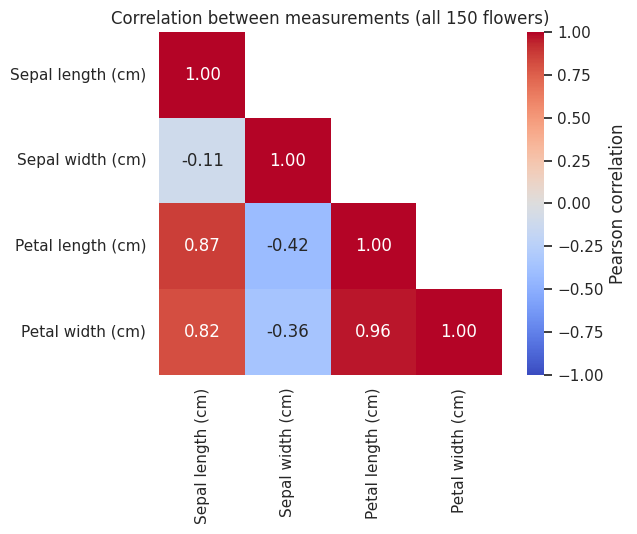

In [12]:
corr_matrix = iris_df[features].corr().rename(index=feature_labels, columns=feature_labels)
upper_triangle = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)  # hide the duplicated half

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr_matrix, mask=upper_triangle, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, square=True, cbar_kws={'label': 'Pearson correlation'})
plt.title('Correlation between measurements (all 150 flowers)')
plt.grid(False)
plt.tight_layout()
plt.show()

**Interpretation:** Petal length and petal width are almost perfectly correlated (0.96), and both are strongly related to sepal length (0.87 and 0.82), so most of the flowers' size differences move along one dimension. Sepal width is the odd one out: it is essentially unrelated to sepal length (−0.12) and moderately *negatively* related to the petal measurements (−0.43 and −0.37). These are pooled correlations across all three species, so the next question checks whether they hold within each species.

## 5. Do these correlations hold *within* each species?

**Analytical Question:** A pooled correlation can be driven by differences *between* groups rather than by a real relationship inside them. Are sepal length vs sepal width and petal length vs petal width related the same way inside each species as they are overall?

In [13]:
pairs = [('SepalLengthCm', 'SepalWidthCm'), ('PetalLengthCm', 'PetalWidthCm')]

# Correlation for all flowers pooled together, then for each species separately
within_corr = pd.DataFrame({
    f"{x.replace('Cm', '')} vs {y.replace('Cm', '')}": {
        'All species (pooled)': iris_df[x].corr(iris_df[y]),
        **{sp: grp[x].corr(grp[y]) for sp, grp in iris_df.groupby('Species')},
    }
    for x, y in pairs
}).round(2)
within_corr

,SepalLength vs SepalWidth,PetalLength vs PetalWidth
All species (pooled),-0.11,0.96
Iris-setosa,0.75,0.31
Iris-versicolor,0.53,0.79
Iris-virginica,0.46,0.32


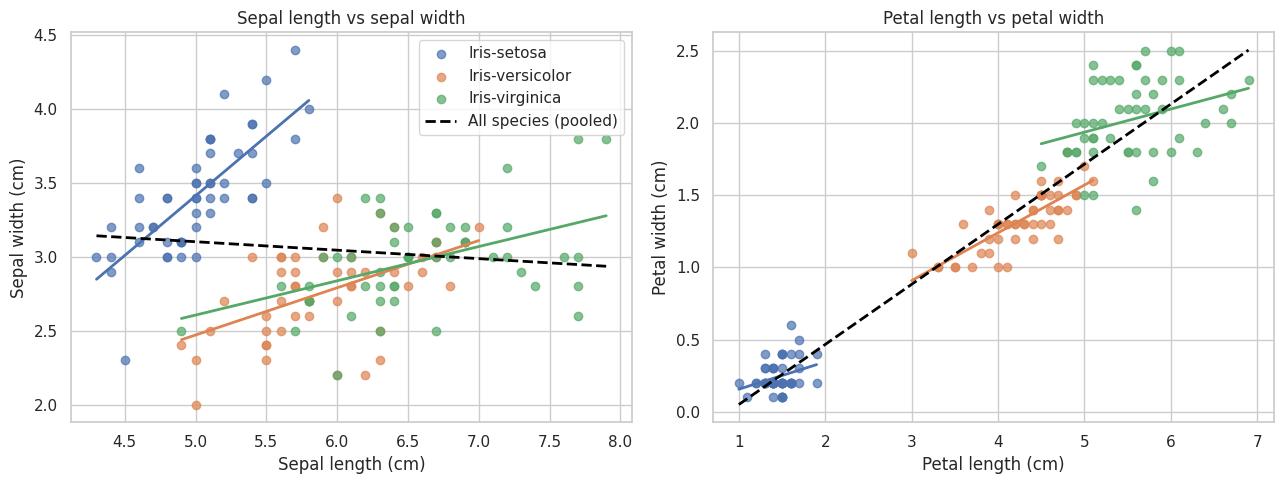

In [14]:
def add_trend_line(ax, data, x, y, **line_kwargs):
    """Draw a least-squares straight line for y ~ x."""
    slope, intercept = np.polyfit(data[x], data[y], 1)
    xs = np.linspace(data[x].min(), data[x].max(), 50)
    ax.plot(xs, slope * xs + intercept, **line_kwargs)


fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (x, y) in zip(axes, pairs):
    for sp in species_order:
        grp = iris_df[iris_df['Species'] == sp]
        ax.scatter(grp[x], grp[y], color=species_colors[sp], alpha=0.7, label=sp)
        add_trend_line(ax, grp, x, y, color=species_colors[sp], linewidth=2)
    add_trend_line(ax, iris_df, x, y, color='black', linestyle='--', linewidth=2, label='All species (pooled)')
    ax.set_xlabel(feature_labels[x])
    ax.set_ylabel(feature_labels[y])
    ax.set_title(f'{feature_labels[x][:-5]} vs {feature_labels[y][:-5].lower()}')

axes[0].legend()
plt.tight_layout()
plt.show()

**Interpretation:** Pooled across all flowers, sepal length and width show no real relationship (−0.12), yet inside *every* species the two are clearly positively correlated (roughly 0.46–0.74). This is **Simpson's paradox**: setosa has short but wide sepals while versicolor and virginica have longer but narrower ones, so mixing the species produces a misleading overall trend, as the slightly falling dashed line shows against the rising coloured lines. The petal pair shows the opposite problem: length and width correlate at 0.96 overall, but only about 0.3 inside setosa and virginica, so much of that strong pooled correlation reflects differences in size *between* species rather than a tight link inside each one. Relationships should always be checked within groups before trusting a pooled correlation.

## 6. Are there unusual measurements within a species?

**Analytical Question:** Which flowers have a measurement that is unusually far from the rest of their own species (values beyond 1.5 × IQR from the quartiles), and are any of them extreme enough to worry about?

In [15]:
long_df = iris_df.melt(id_vars=['Id', 'Species'], value_vars=features, var_name='Feature', value_name='Value')

# Quartiles are computed per species and feature, so a flower is only compared with its own species
grouped = long_df.groupby(['Species', 'Feature'])['Value']
q1 = grouped.transform(lambda s: s.quantile(0.25))
q3 = grouped.transform(lambda s: s.quantile(0.75))
iqr = q3 - q1

is_outlier = (long_df['Value'] < q1 - 1.5 * iqr) | (long_df['Value'] > q3 + 1.5 * iqr)
outliers_df = long_df[is_outlier].sort_values(['Species', 'Feature', 'Id']).reset_index(drop=True)

print(f'{len(outliers_df)} of {len(long_df)} measurements flagged as outliers')
outliers_df

11 of 600 measurements flagged as outliers


,Id,Species,Feature,Value
0,14,Iris-setosa,PetalLengthCm,1.1
1,23,Iris-setosa,PetalLengthCm,1.0
2,25,Iris-setosa,PetalLengthCm,1.9
3,45,Iris-setosa,PetalLengthCm,1.9
4,24,Iris-setosa,PetalWidthCm,0.5
5,44,Iris-setosa,PetalWidthCm,0.6
6,99,Iris-versicolor,PetalLengthCm,3.0
7,107,Iris-virginica,SepalLengthCm,4.9
8,118,Iris-virginica,SepalWidthCm,3.8
9,120,Iris-virginica,SepalWidthCm,2.2


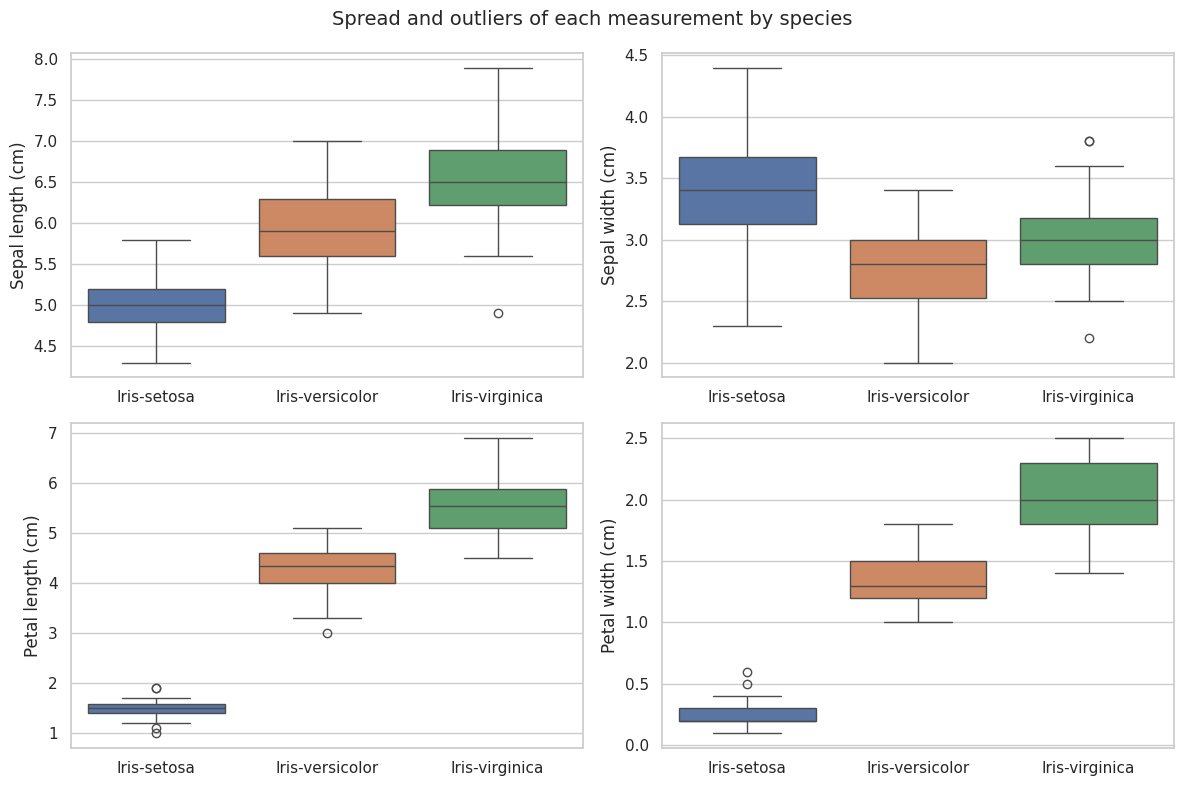

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.ravel(), features):
    sns.boxplot(data=iris_df, x='Species', y=feature, order=species_order, hue='Species',
                palette=species_colors, legend=False, ax=ax)
    ax.set_ylabel(feature_labels[feature])
    ax.set_xlabel('')

fig.suptitle('Spread and outliers of each measurement by species', fontsize=14)
plt.tight_layout()
plt.show()

**Interpretation:** About a dozen of the 600 measurements are flagged, most of them in setosa, whose petals are so tightly clustered that even slightly larger values fall outside the whiskers. Almost all are marginal (only just beyond the limit) and sit close to the rest of their species. The most notable is flower 107, a virginica with a sepal length of only 4.9 cm (typical of setosa) and the shortest petals of any virginica (4.5 cm), which places it in the zone where versicolor and virginica overlap (see question 7). It is an unusual flower rather than an error: no value looks like a data-entry mistake, so nothing needs to be removed or corrected.

## 7. Which measurement separates the species best?

**Analytical Question:** For each measurement, is there a clear gap between setosa and the other two species, and how many versicolor/virginica flowers fall in the range that both species share? (The versicolor vs virginica split is the harder one to make.)

In [17]:
pair_species = ['Iris-versicolor', 'Iris-virginica']


def shared_range_count(data, feature):
    """Number of versicolor/virginica flowers whose value lies in the range that both species cover."""
    pair = data[data['Species'].isin(pair_species)]
    by_species = pair.groupby('Species')[feature]
    low, high = by_species.min().max(), by_species.max().min()
    return int(pair[feature].between(low, high).sum())


mins = iris_df.groupby('Species')[features].min()
maxs = iris_df.groupby('Species')[features].max()

separation_df = pd.DataFrame({
    # Positive gap = setosa's largest value is still below the smallest value of the other two species
    'Gap: setosa vs others (cm)': (mins.loc[pair_species].min() - maxs.loc['Iris-setosa']).round(1),
    # Counted among the 100 versicolor + virginica flowers
    'Flowers in shared range (of 100)': pd.Series({f: shared_range_count(iris_df, f) for f in features}),
}).sort_values('Flowers in shared range (of 100)')

separation_df.rename(index=feature_labels)

,Gap: setosa vs others (cm),Flowers in shared range (of 100)
Petal length (cm),1.1,37
Petal width (cm),0.4,38
Sepal length (cm),-0.9,88
Sepal width (cm),-2.4,96


**Interpretation:** Only the petal measurements fully separate setosa: there is a clear gap (1.1 cm for petal length, 0.4 cm for petal width) between the largest setosa flower and the smallest flower of the other species, while the sepal ranges overlap heavily (negative gaps). Versicolor and virginica cannot be separated perfectly by any single measurement, but the petal measurements are far better: 37–38 of the 100 flowers sit in the shared range, compared with 88 for sepal length and 96 for sepal width. Sepals are almost useless for distinguishing these two species, and even the best raw measurement leaves more than a third of the flowers ambiguous, which motivates the next question.

## 8. Can a combined measurement separate versicolor and virginica better?

**Analytical Question:** Petal length and width are strongly correlated and each still overlaps between versicolor and virginica. Does combining them into a single *petal area* (length × width) reduce the overlap? For contrast, are sepal area and a petal-to-sepal length ratio any better?

In [18]:
iris_derived = iris_df.assign(
    PetalArea=iris_df['PetalLengthCm'] * iris_df['PetalWidthCm'],
    SepalArea=iris_df['SepalLengthCm'] * iris_df['SepalWidthCm'],
    PetalToSepalLength=iris_df['PetalLengthCm'] / iris_df['SepalLengthCm'],
)

compare_features = ['PetalLengthCm', 'PetalWidthCm', 'PetalArea', 'SepalArea', 'PetalToSepalLength']

overlap_comparison = pd.Series(
    {f: shared_range_count(iris_derived, f) for f in compare_features},
    name='Versicolor/virginica flowers in shared range (of 100)',
).sort_values()
overlap_comparison

,Versicolor/virginica flowers in shared range (of 100)
PetalArea,10
PetalLengthCm,37
PetalWidthCm,38
PetalToSepalLength,41
SepalArea,91


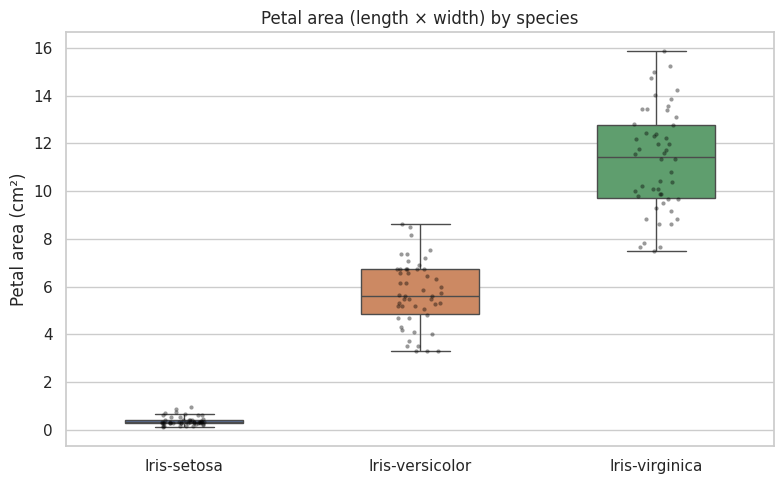

In [19]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=iris_derived, x='Species', y='PetalArea', order=species_order, hue='Species',
            palette=species_colors, legend=False, width=0.5, showfliers=False)
sns.stripplot(data=iris_derived, x='Species', y='PetalArea', order=species_order,
              color='black', alpha=0.4, size=3)
plt.title('Petal area (length × width) by species')
plt.ylabel('Petal area (cm²)')
plt.xlabel('')
plt.tight_layout()
plt.show()

**Interpretation:** Combining the two petal measurements works: petal area leaves only about 10 of the 100 versicolor/virginica flowers in the shared range, versus 37–38 for petal length or width alone, and the chart shows the two boxes almost completely apart. The other engineered features do not help: sepal area (around 90 flowers in the shared range) is as uninformative as the raw sepal measurements, and the petal-to-sepal ratio (about 40) is no better than petal length. New features have to be tested rather than assumed to help, and the useful one here is the one built from the measurements that already separated the species. Note that the shared-range count uses each species' minimum and maximum, so it is sensitive to single extreme flowers; it is a descriptive measure of overlap, not a prediction.

## Key Insights / Conclusion

- **Clean, balanced data.** 150 flowers, 50 per species, no missing values, so species can be compared directly.
- **The petals identify the species; the sepals barely do.** Petal length and width completely separate setosa, and leave only 37–38 of the 100 versicolor/virginica flowers in a shared range, versus 88–96 for the sepal measurements. Sepal width is nearly uninformative on its own.
- **Species explain the petal variation, not the sepal variation.** The coefficient of variation of petal length/width is 47–64% across all flowers but only about 10–15% inside versicolor and virginica; for sepals the drop is much smaller (about 14% overall vs 7–11% within species).
- **Setosa is distinct but not simply "smaller".** It has by far the smallest petals (mean length 1.46 cm vs 4.26 and 5.55) yet the widest sepals (3.43 cm), so species do not rank consistently across features.
- **Pooled correlations can mislead.** Sepal length and width are uncorrelated overall (−0.12) but positively correlated inside every species (Simpson's paradox), and the 0.96 petal length–width correlation drops to about 0.3 within setosa and virginica.
- **Versicolor vs virginica is the hard pair, and combining features helps.** Petal area (length × width) cuts the ambiguous flowers from 37–38 down to about 10 of 100, while other engineered features (sepal area, petal-to-sepal ratio) add nothing.
- **Outliers are mild.** About a dozen of 600 measurements fall just outside the 1.5 × IQR limits, mostly in setosa, and none looks like an error.

**Limitations:** With only 150 observations (50 per species), range-based overlap counts are sensitive to a few extreme flowers, and everything here is descriptive: it shows what separates the species in this sample, not how well a model would generalise.